# Part 2, Topic 1: CPA Attack on 32bit AES (MAIN)

---
NOTE: This lab references some (commercial) training material on [ChipWhisperer.io](https://www.ChipWhisperer.io). You can freely execute and use the lab per the open-source license (including using it in your own courses if you distribute similarly), but you must maintain notice about this source location. Consider joining our training course to enjoy the full experience.

---

**SUMMARY:** *So far, we've been focusing on a single implementation of AES, TINYAES128C (or AVRCRYPTOLIB, if you're on XMEGA). TINYAES128C, which is designed to run on a variety of microcontrollers, doesn't make any implementation specific optimizations. In this lab, we'll look at how we can break a 32-bit optimized version of AES using a CPA attack.*

**LEARNING OUTCOMES:**

* Understanding how AES can be optimized on 32-bit platforms.
* Attacking an optimized version of AES using CPA

## Optimizing AES

A 32-bit machine can operate on 32-bit words, so it seems wasteful to use the same 8-bit operations. For example, if we look at the SBox operation:

$
b = sbox(state) = sbox(\left[ \begin{array}
& S0 & S4 & S8 & S12 \\
S1 & S5 & S9 & S13 \\
S2 & S6 & S10 & S14 \\
S3 & S7 & S11 & S15
\end{array} \right]) = \left[ \begin{array}
& S0 & S4 & S8 & S12 \\
S5 & S9 & S13 & S1 \\
S10 & S14 & S2 & S6 \\
S15 & S3 & S7 & S11
\end{array} \right]
$

we could consider each row as a 32-bit number and do three bitwise rotates instead of moving a bunch of stuff around in memory. Even better, we can speed up AES considerably by generating 32-bit lookup tables, called T-Tables, as was described in the book [The Design of Rijndael](http://www.springer.com/gp/book/9783540425809) which was published by the authors of AES.

In order to take full advantage of our 32 bit machine, we can examine a typical round of AES. With the exception of the final round, each round looks like:

$\text{a = Round Input}$

$\text{b = SubBytes(a)}$

$\text{c = ShiftRows(b)}$

$\text{d = MixColumns(c)}$

$\text{a' = AddRoundKey(d) = Round Output}$

We'll leave AddRoundKey the way it is. The other operations are:

$b_{i,j} = \text{sbox}[a_{i,j}]$

$\left[ \begin{array} { c } { c _ { 0 , j } } \\ { c _ { 1 , j } } \\ { c _ { 2 , j } } \\ { c _ { 3 , j } } \end{array} \right] = \left[ \begin{array} { l } { b _ { 0 , j + 0 } } \\ { b _ { 1 , j + 1 } } \\ { b _ { 2 , j + 2 } } \\ { b _ { 3 , j + 3 } } \end{array} \right]$

$\left[ \begin{array} { l } { d _ { 0 , j } } \\ { d _ { 1 , j } } \\ { d _ { 2 , j } } \\ { d _ { 3 , j } } \end{array} \right] = \left[ \begin{array} { l l l l } { 02 } & { 03 } & { 01 } & { 01 } \\ { 01 } & { 02 } & { 03 } & { 01 } \\ { 01 } & { 01 } & { 02 } & { 03 } \\ { 03 } & { 01 } & { 01 } & { 02 } \end{array} \right] \times \left[ \begin{array} { c } { c _ { 0 , j } } \\ { c _ { 1 , j } } \\ { c _ { 2 , j } } \\ { c _ { 3 , j } } \end{array} \right]$

Note that the ShiftRows operation $b_{i, j+c}$ is a cyclic shift and the matrix multiplcation in MixColumns denotes the xtime operation in GF($2^8$).

It's possible to combine all three of these operations into a single line. We can write 4 bytes of $d$ as the linear combination of four different 4 byte vectors:

$\left[ \begin{array} { l } { d _ { 0 , j } } \\ { d _ { 1 , j } } \\ { d _ { 2 , j } } \\ { d _ { 3 , j } } \end{array} \right] = \left[ \begin{array} { l } { 02 } \\ { 01 } \\ { 01 } \\ { 03 } \end{array} \right] \operatorname { sbox } \left[ a _ { 0 , j + 0 } \right] \oplus \left[ \begin{array} { l } { 03 } \\ { 02 } \\ { 01 } \\ { 01 } \end{array} \right] \operatorname { sbox } \left[ a _ { 1 , j + 1 } \right] \oplus \left[ \begin{array} { c } { 01 } \\ { 03 } \\ { 02 } \\ { 01 } \end{array} \right] \operatorname { sbox } \left[ a _ { 2 , j + 2 } \right] \oplus \left[ \begin{array} { c } { 01 } \\ { 01 } \\ { 03 } \\ { 02 } \end{array} \right] \operatorname { sbox } \left[ a _ { 3 , j + 3 } \right]$

Now, for each of these four components, we can tabulate the outputs for every possible 8-bit input:

$T _ { 0 } [ a ] = \left[ \begin{array} { l l } { 02 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 03 \times \operatorname { sbox } [ a ] } \end{array} \right]$

$T _ { 1 } [ a ] = \left[ \begin{array} { l } { 03 \times \operatorname { sbox } [ a ] } \\ { 02 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \end{array} \right]$

$T _ { 2 } [ a ] = \left[ \begin{array} { l l } { 01 \times \operatorname { sbox } [ a ] } \\ { 03 \times \operatorname { sbox } [ a ] } \\ { 02 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \end{array} \right]$

$T _ { 3 } [ a ] = \left[ \begin{array} { l l } { 01 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 03 \times \operatorname { sbox } [ a ] } \\ { 02 \times \operatorname { sbox } [ a ] } \end{array} \right]$

These tables have 2^8 different 32-bit entries, so together the tables take up 4 kB. Finally, we can quickly compute one round of AES by calculating

$\left[ \begin{array} { l } { d _ { 0 , j } } \\ { d _ { 1 , j } } \\ { d _ { 2 , j } } \\ { d _ { 3 , j } } \end{array} \right] = T _ { 0 } \left[ a _ { 0 } , j + 0 \right] \oplus T _ { 1 } \left[ a _ { 1 } , j + 1 \right] \oplus T _ { 2 } \left[ a _ { 2 } , j + 2 \right] \oplus T _ { 3 } \left[ a _ { 3 } , j + 3 \right]$

All together, with AddRoundKey at the end, a single round now takes 16 table lookups and 16 32-bit XOR operations. This arrangement is much more efficient than the traditional 8-bit implementation. There are a few more tradeoffs that can be made: for instance, the tables only differ by 8-bit shifts, so it's also possible to store only 1 kB of lookup tables at the expense of a few rotate operations.

While the TINYAES128C library we've been using doesn't make this optimization, another library included with ChipWhisperer called MBEDTLS does.

In [5]:
%%bash
cd ../../../firmware/mcu/simpleserial-aes
cp objdir/makefile Makefile
echo "--- ficheiros agora na pasta: ---"
ls Makefile simpleserial-aes.c

--- ficheiros agora na pasta: ---
Makefile
simpleserial-aes.c


In [12]:
SCOPETYPE = 'OPENADC'
PLATFORM  = 'CW308_SAM4S'        # ← o vosso alvo (não CWLITEARM)
SS_VER    = 'SS_VER_1_1'
CRYPTO_TARGET = 'TINYAES128C'    # modelo SBox limpo (o que a pipeline usa)

In [55]:
%run "../../Setup_Scripts/Setup_Generic.ipynb"

INFO: Caught exception on reconnecting to target - attempting to reconnect to scope first.
INFO: This is a work-around when USB has died without Python knowing. Ignore errors above this line.
INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 131124                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2     

In [27]:
%%bash -s "$PLATFORM" "$CRYPTO_TARGET" "$SS_VER"
cd ../../../firmware/mcu/simpleserial-aes
make clean
make PLATFORM=$1 CRYPTO_TARGET=$2 SS_VER=$3

No CRYPTO_TARGET passed - defaulting to TINYAES128C
Building for platform  with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_1_1


.././hal/Makefile.hal:299: *** Invalid or empty PLATFORM: NONE. Known platforms: 
+-------------------------------------------------------+
| PLATFORM      | DESCRIPTION                           |
+=======================================================+
| MOST COMMON TARGETS                                   |
+=======================================================+
+-------------------------------------------------------+
| CWLITEARM     | CW-Lite Arm (Alias for CW308_STM32F3) |
+-------------------------------------------------------+
| CWNANO        | CW-Lite Nano (STM32F0_NANO)           |
+-------------------------------------------------------+
| CWHUSKY       | CW-Husky (Alias for CW308_SAM4L)      |
+-------------------------------------------------------+
+=======================================================+
| AVR/XMEGA Targets (8-Bit RISC)                        |
+=======================================================+
+-----------------------------------------------

Building for platform CW308_SAM4S with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
Blank crypto options, building for AES128
.
Welcome to another exciting ChipWhisperer target build!!
arm-none-eabi-gcc (15:13.2.rel1-2) 13.2.1 20231009
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CW308_SAM4S 
.
Compiling:
-en     simpleserial-aes.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/startup_sam4s.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/sam4s_hal.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/uart.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/pio.c ...
-e Done!
.
Compiling:
-en     .././hal//sam4s/system_sam4s.c ...
-e Done!
.
Compiling:
-en     .././h

/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-closer.o): in function `_close_r':
/build/newlib-38V0JC/newlib-4.4.0.20231231/build_nano/arm-none-eabi/thumb/v7e-m/nofp/newlib/../../../../../../newlib/libc/reent/closer.c:47:(.text+0xc): warning: _close is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-lseekr.o): in function `_lseek_r':
/build/newlib-38V0JC/newlib-4.4.0.20231231/build_nano/arm-none-eabi/thumb/v7e-m/nofp/newlib/../../../../../../newlib/libc/reent/lseekr.c:49:(.text+0x14): warning: _lseek is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-readr.o): in function `_r

/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-closer.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-lseekr.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-readr.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/13.2.1/../../../arm-none-eabi/lib/thumb/v7e-m/nofp/libg_nano.a(libc_a-writer.o): note: the message above does not take linker garbage collection into account
-

In [45]:
!pip install intelhex


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


You probably can't even pick out the different AES rounds anymore (whereas it was pretty obvious on TINYAES128C). MBED is also way faster - we only got part way into round 2 with 5000 samples of TINYAES, but with MBED we can finish the entire encryption in less than 5000 samples! Two questions we need to answer now are:

1. Is it possible for us to break this AES implementation?
1. If so, what sort of leakage model do we need?

As it turns out, the answers are:

1. Yes!
1. We can continue to use the same leakage model - the SBox output

This might come as a surprise, but it's true! Two of the t_table lookups are just the sbox[key^plaintext] that we used before. Try the analysis for yourself now and verify that this is correct:

In [65]:
from intelhex import IntelHex

bin_path = r"C:\Users\ruilo\OneDrive\Imagens\Ambiente de Trabalho\AAU\3.P7 - Semestre Project\combined.bin"

ih = IntelHex()
ih.loadbin(bin_path, offset=0x400000)
ih.write_hex_file("combined.hex")

cw.program_target(scope, prog, "combined.hex")
print("defesa (combined.bin) gravada no SAM4S")

flashed: C:\Users\ruilo\OneDrive\Imagens\Ambiente de Trabalho\AAU\3.P7 - Semestre Project\customer-CW308_SAM4S.bin
resposta crua: ''
>>> vazio -> não respondeu (provável HardFault)


In [64]:
clear errors

## Improving the Model

While this model works alright for mbedtls, you probably wouldn't be surprised if it wasn't the best model to attack with. Instead, we can attack the full T-Tables. Returning again to the T-Tables:

$T _ { 0 } [ a ] = \left[ \begin{array} { l l } { 02 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 03 \times \operatorname { sbox } [ a ] } \end{array} \right]$

$T _ { 1 } [ a ] = \left[ \begin{array} { l } { 03 \times \operatorname { sbox } [ a ] } \\ { 02 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \end{array} \right]$

$T _ { 2 } [ a ] = \left[ \begin{array} { l l } { 01 \times \operatorname { sbox } [ a ] } \\ { 03 \times \operatorname { sbox } [ a ] } \\ { 02 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \end{array} \right]$

$T _ { 3 } [ a ] = \left[ \begin{array} { l l } { 01 \times \operatorname { sbox } [ a ] } \\ { 01 \times \operatorname { sbox } [ a ] } \\ { 03 \times \operatorname { sbox } [ a ] } \\ { 02 \times \operatorname { sbox } [ a ] } \end{array} \right]$

we can see that for each T-Table lookup, the following is accessed:

$\operatorname {sbox}[a]$, $\operatorname {sbox}[a]$, $2 \times \operatorname {sbox}[a]$, $3 \times \operatorname {sbox}[a]$

so instead of just taking the Hamming weight of the SBox, we can instead take the Hamming weight of this whole access:

$h = \operatorname {hw}[\operatorname {sbox}[a]] + \operatorname {hw}[\operatorname {sbox}[a]] + \operatorname {hw}[2 \times \operatorname {sbox}[a]] + \operatorname {hw}[3 \times \operatorname {sbox}[a]]$

Again, ChipWhisperer already has this model built in, which you can access with `cwa.leakage_models.t_table`. Retry your CPA attack with this new leakage model:

In [60]:
import numpy as np
from tqdm.notebook import trange

N = 2000
ktp = cw.ktp.Basic()
project = cw.create_project("traces/32bit_AES.cwp", overwrite=True)

textins = []
for i in trange(N, desc='Capturing'):
    key, text = ktp.next()
    tr = cw.capture_trace(scope, target, text, key)
    if tr is None:
        continue
    project.traces.append(tr)
    textins.append(list(text))
project.save()

np.savez('capture_nodef.npz',
         traces=np.array([t.wave for t in project.traces], dtype=np.float32),
         textin=np.array(textins, dtype=np.uint8),
         key=np.array(list(key), dtype=np.uint8))
print("guardado:", len(project.traces), "traces")

Capturing:   0%|          | 0/2000 [00:00<?, ?it/s]

(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:732) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 13
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:732) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 12
(ChipWhisperer Scope WARNING|File __init__.py:517) Timeout happened during capture
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:732) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 13
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:732) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 12
(ChipWhisperer Scope WARNING|File __init__.py:517) Timeout happened during capture
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:732) Timeout in OpenADC capture(), no trigger seen! Trigger forced, data is invalid. Status: 13
(ChipWhisperer Scope WARNING|File _OpenADCInterface.py:732) Timeout in OpenADC 

KeyboardInterrupt: 

In [38]:
cw.plot(project.waves[0])

:Curve   [x]   (y)

In [39]:
import chipwhisperer.analyzer as cwa
leak_model = cwa.leakage_models.sbox_output
attack = cwa.cpa(project, leak_model)
results = attack.run(cwa.get_jupyter_callback(attack))
results

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
PGE=,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,2B0.853,7E0.903,150.833,160.834,280.861,AE0.871,D20.842,A60.910,AB0.759,F70.871,150.808,880.914,090.736,CF0.877,4F0.837,3C0.850
1,A90.476,160.453,300.479,DD0.486,900.469,5F0.457,A80.480,B30.457,900.480,180.471,5A0.522,EB0.469,9E0.470,CB0.443,960.498,1A0.463
2,F50.448,270.448,3A0.478,3B0.467,350.458,360.449,8B0.475,3D0.456,740.464,4D0.460,560.487,760.456,6E0.461,7E0.441,000.449,070.455
3,8C0.442,8C0.447,2C0.452,4C0.464,FD0.454,740.445,850.453,B20.450,2E0.448,470.453,300.482,8E0.452,610.452,4F0.439,130.440,FC0.450
4,7B0.442,850.436,040.448,B20.446,A10.448,270.442,870.451,990.448,7B0.440,410.446,9B0.481,BD0.450,520.445,F00.438,3A0.436,1F0.444


chave recuperada: True
rho por byte: [0.853 0.903 0.833 0.834 0.861 0.871 0.842 0.91  0.759 0.871 0.808 0.914
 0.736 0.877 0.837 0.85 ]
Fisher prevê (byte 0): 20 traces
MTD: 50
saved sca_curves.png


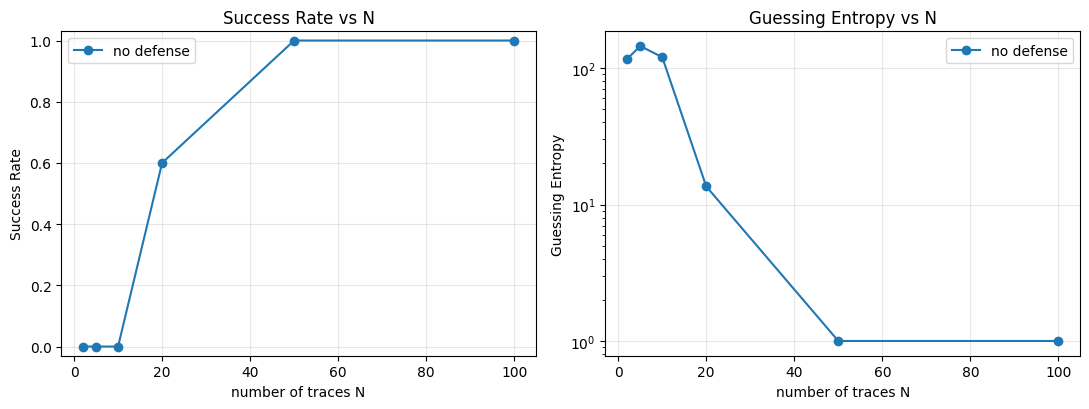

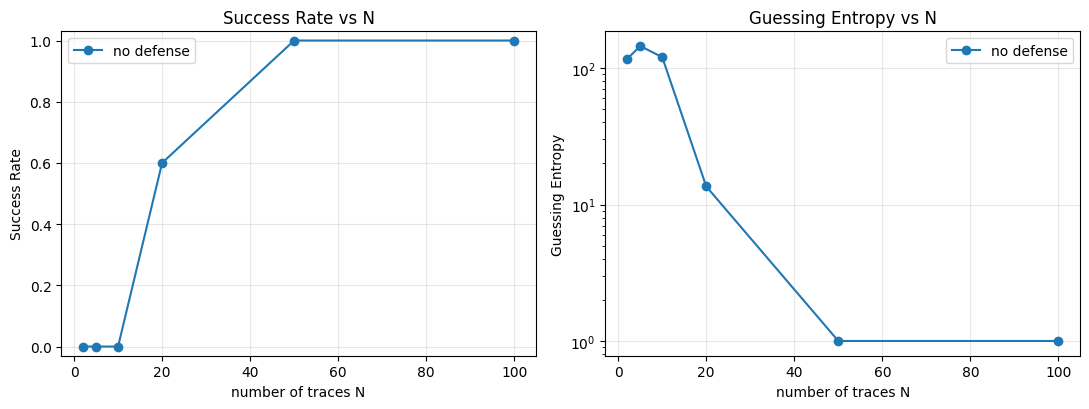

In [41]:
import numpy as np, sca_cpa_pipeline as P

d = np.load('capture_nodef.npz')
ranks, rho = P.cpa_ranks(d['traces'], d['textin'], d['key'])
print("chave recuperada:", bool(np.all(ranks == 1)))
print("rho por byte:", np.round(rho, 3))
print("Fisher prevê (byte 0):", round(P.fisher_traces(rho[0])), "traces")

Ns = [10, 20, 50, 100, 500, 1000, 2000]
SR, GE = P.sr_ge_vs_traces(d['traces'], d['textin'], d['key'], Ns, R=30)
print("MTD:", P.mtd_from_curve(Ns, GE))
P.plot_comparison(Ns, SR, GE)

In [42]:
from Crypto.Cipher import AES          # pip install pycryptodome if missing

# 1) the key the attack recovered
recovered = bytes(results.key_guess())
print("="*60)
print("RECOVERED KEY:", recovered.hex())
print("="*60)

cipher = AES.new(recovered, AES.MODE_ECB)

# 2) show the first 5 encryptions in detail
print("\n--- detailed check (first 5 traces) ---")
for i, tr in enumerate(project.traces[:5]):
    pt      = bytes(tr.textin)                 # plaintext you sent to the chip
    ct_chip = bytes(tr.textout)                # ciphertext the CHIP returned
    ct_pred = AES.new(recovered, AES.MODE_ECB).encrypt(pt)  # you encrypt with the recovered key

    match = (ct_pred == ct_chip)
    print(f"\nTrace {i}")
    print(f"  plaintext        : {pt.hex()}")
    print(f"  chip  ciphertext : {ct_chip.hex()}")
    print(f"  your  ciphertext : {ct_pred.hex()}")
    print(f"  match            : {match}")

# 3) full tally over many traces
print("\n--- full check ---")
n = min(100, len(project.traces))
ok = 0
for tr in project.traces[:n]:
    pt      = bytes(tr.textin)
    ct_chip = bytes(tr.textout)
    ct_pred = AES.new(recovered, AES.MODE_ECB).encrypt(pt)
    ok += (ct_pred == ct_chip)

print(f"{ok}/{n} ciphertexts match")
print(">>> KEY CONFIRMED <<<" if ok == n else ">>> MISMATCH — something is wrong <<<")

RECOVERED KEY: 2b7e151628aed2a6abf7158809cf4f3c

--- detailed check (first 5 traces) ---

Trace 0
  plaintext        : d4f4aa810656427a749cb55b5ce86b07
  chip  ciphertext : cb7f1466111a2a6976ddfd7639862eab
  your  ciphertext : cb7f1466111a2a6976ddfd7639862eab
  match            : True

Trace 1
  plaintext        : f5ecef68ecfcadf4341eae444d04cbb3
  chip  ciphertext : e25ccc446247c847289a5de9c6598582
  your  ciphertext : e25ccc446247c847289a5de9c6598582
  match            : True

Trace 2
  plaintext        : 25f2342dd4fbc78badd1144eda8da73a
  chip  ciphertext : cd80090a14bf3231fcd831acac503492
  your  ciphertext : cd80090a14bf3231fcd831acac503492
  match            : True

Trace 3
  plaintext        : 7acf41b30cc84015f159e26207466cca
  chip  ciphertext : 7e620c6226b2b721f60effc57b5dabad
  your  ciphertext : 7e620c6226b2b721f60effc57b5dabad
  match            : True

Trace 4
  plaintext        : 971528f37c1f8c37026a615c00a6735b
  chip  ciphertext : fb87575289085f12082bdc476f18c27f
  your

Did this attack work better than the previous one?

## T-Tables for Decryption:

Recall that the last round of AES is different than the rest of the rounds. Instead of it applying `subbytes`, `shiftrows`, `mixcolumns`, and `addroundkey`, it leaves out `mixcolumns`. You might expect that this means that decryption doesn't use a reverse T-Table in the first decryption round, but this isn't necessarily the case! Since `mixcolumns` is a linear operation, $\operatorname{mixcolumns}( \operatorname{key} + \operatorname{state})$ is equal to  $\operatorname{mixcolumns}(\operatorname{key}) + \operatorname{mixcolumns}(\operatorname{state})$. Again, this is the approach that MBEDTLS takes, so we would be able to use the reverse T-Table to attack decryption.